# Challenge Básico: Análisis de la Base de Datos Global de Terrorismo (GTD)
## Usando PySpark.Pandas (API Koalas)

**Autor:** Carlos Pulido Rosas

**Universidad:** Universidad de Guadalajara - Campus CUCEA

**Maestria:** Ciencia de los Datos

**Materia:** Procesamiento de Grandes Bases de Datos

**Dataset:** Global Terrorism Database (GTD)

**Fuente:** [Kaggle - Global Terrorism Database](https://www.kaggle.com/datasets/START-UMD/gtd)

---

## Descripción del Dataset

La Global Terrorism Database (GTD) es una base de datos de código abierto que contiene información sobre más de **180,000 ataques terroristas** en todo el mundo desde **1970 hasta 2017**.

**Características principales:**
- **135 columnas** con información detallada de cada ataque
- Datos sobre fecha, ubicación, armas utilizadas, objetivos, víctimas, grupos responsables
- Cobertura global de ataques domésticos e internacionales
- Aproximadamente 155 MB de datos

## Objetivo

Realizar un análisis exploratorio utilizando **PySpark.Pandas (Koalas API)** para:
- Identificar patrones temporales y geográficos del terrorismo
- Analizar tipos de ataques y objetivos
- Estudiar la evolución del terrorismo a lo largo del tiempo
- Identificar regiones y grupos más activos
- Generar visualizaciones significativas

## ¿Qué es PySpark.Pandas (Koalas)?

PySpark.Pandas es una API que permite usar sintaxis de pandas con el poder distribuido de Apache Spark. Anteriormente conocida como **Koalas**, fue integrada oficialmente en PySpark 3.2+.

## 1. Configuración e Importación de Librerías

In [20]:
# Importar librerías necesarias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import warnings
import kagglehub
import shutil
import os

# Configurar advertencias
warnings.filterwarnings('ignore')

# Configurar estilo de visualizaciones
sns.set_style('whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (14, 7)

print("✓ Librerías importadas exitosamente")

✓ Librerías importadas exitosamente


## 1.1 Configuración de PySpark con Pandas API (Koalas)

In [21]:
# Configuración especial de Spark para Windows
import pyspark.pandas as ps  # API de Koalas/pandas para PySpark
from pyspark.sql import SparkSession
from pyspark import __version__ as pyspark_version
import os

# Detener cualquier sesión de Spark existente
try:
    spark = SparkSession.getActiveSession()
    if spark:
        spark.stop()
        print("Sesión anterior de Spark detenida")
except:
    pass

# Crear nueva sesión con configuración para Windows
spark = SparkSession.builder \
    .appName("GTD_Analysis") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "false") \
    .config("spark.python.worker.reuse", "false") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .config("spark.executor.instances", "1") \
    .config("spark.sql.shuffle.partitions", "4") \
    .master("local[1]") \
    .getOrCreate()

print("✓ Sesión de Spark configurada para Windows")
print(f"Versión de Spark: {spark.version}")

# Configurar PySpark.Pandas para usar esta sesión
ps.set_option('compute.default_index_type', 'distributed')
ps.set_option('compute.ops_on_diff_frames', True)
ps.set_option('compute.max_rows', 1000)  # Limitar filas para display

print("✓ PySpark.Pandas configurado correctamente")

Sesión anterior de Spark detenida
✓ Sesión de Spark configurada para Windows
Versión de Spark: 3.5.6
✓ PySpark.Pandas configurado correctamente


## 2. Carga de Datos con PySpark.Pandas

In [22]:
# Cargar el dataset GTD usando KaggleHub y PySpark.Pandas

print("Paso 1: Descargando dataset desde Kaggle con KaggleHub...")
print("-" * 60)

# Descargar dataset usando KaggleHub
path = kagglehub.dataset_download("START-UMD/gtd")

print(f"✓ Dataset descargado desde Kaggle")
print(f"  Ruta original: {path}\n")

# Encontrar el archivo CSV en la ruta descargada
archivos_csv = [f for f in os.listdir(path) if f.endswith('.csv')]
archivo_origen = os.path.join(path, archivos_csv[0])

# Copiar a la carpeta actual
carpeta_actual = os.getcwd()
archivo_destino = os.path.join(carpeta_actual, archivos_csv[0])

print(f"Paso 2: Copiando archivo a carpeta actual...")
shutil.copy(archivo_origen, archivo_destino)
print(f"✓ Archivo copiado: {archivos_csv[0]}\n")

print("Paso 3: Cargando con PySpark.Pandas (Koalas API)...")
print("-" * 60)
print("Esto puede tardar unos minutos debido al tamaño del dataset...\n")

# Cargar con PySpark.Pandas desde la carpeta actual
df = ps.read_csv(archivo_destino, encoding='ISO-8859-1')

print(f"✓ Dataset cargado exitosamente usando PySpark.Pandas")
print(f"  Archivo local: {archivos_csv[0]}")
print(f"  Tipo de objeto: {type(df)}")
print(f"  Dimensiones: {df.shape}")
print(f"  Framework: Distribuido con Apache Spark")
print(f"  Sintaxis: Pandas (Koalas API)")

Paso 1: Descargando dataset desde Kaggle con KaggleHub...
------------------------------------------------------------
✓ Dataset descargado desde Kaggle
  Ruta original: C:\Users\carlo\.cache\kagglehub\datasets\START-UMD\gtd\versions\3

Paso 2: Copiando archivo a carpeta actual...
✓ Archivo copiado: globalterrorismdb_0718dist.csv

Paso 3: Cargando con PySpark.Pandas (Koalas API)...
------------------------------------------------------------
Esto puede tardar unos minutos debido al tamaño del dataset...

✓ Dataset cargado exitosamente usando PySpark.Pandas
  Archivo local: globalterrorismdb_0718dist.csv
  Tipo de objeto: <class 'pyspark.pandas.frame.DataFrame'>
  Dimensiones: (181691, 135)
  Framework: Distribuido con Apache Spark
  Sintaxis: Pandas (Koalas API)


In [23]:
# Mostrar primeras filas (sintaxis idéntica a pandas)
print("Primeras 5 filas del dataset:")
df.head()

Primeras 5 filas del dataset:


,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,region_txt,provstate,city,latitude,longitude,specificity,vicinity,location,summary,crit1,crit2,crit3,doubtterr,alternative,alternative_txt,multiple,success,suicide,attacktype1,attacktype1_txt,attacktype2,attacktype2_txt,attacktype3,attacktype3_txt,targtype1,targtype1_txt,targsubtype1,targsubtype1_txt,corp1,target1,natlty1,natlty1_txt,targtype2,targtype2_txt,targsubtype2,targsubtype2_txt,corp2,target2,natlty2,natlty2_txt,targtype3,targtype3_txt,targsubtype3,targsubtype3_txt,corp3,target3,natlty3,natlty3_txt,gname,gsubname,gname2,gsubname2,gname3,gsubname3,motive,guncertain1,guncertain2,guncertain3,individual,nperps,nperpcap,claimed,claimmode,claimmode_txt,claim2,claimmode2,claimmode2_txt,claim3,claimmode3,claimmode3_txt,compclaim,weaptype1,weaptype1_txt,weapsubtype1,weapsubtype1_txt,weaptype2,weaptype2_txt,weapsubtype2,weapsubtype2_txt,weaptype3,weaptype3_txt,weapsubtype3,weapsubtype3_txt,weaptype4,weaptype4_txt,weapsubtype4,weapsubtype4_txt,weapdetail,nkill,nkillus,nkillter,nwound,nwoundus,nwoundte,property,propextent,propextent_txt,propvalue,propcomment,ishostkid,nhostkid,nhostkidus,nhours,ndays,divert,kidhijcountry,ransom,ransomamt,ransomamtus,ransompaid,ransompaidus,ransomnote,hostkidoutcome,hostkidoutcome_txt,nreleased,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,197000000001,1970,7,2,None,0,None,58,Dominican Republic,2,Central America & Caribbean,None,Santo Domingo,18.456792,-69.951164,1,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,14,Private Citizens & Property,68,Named Civilian,None,Julio Guzman,58,Dominican Republic,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,MANO-D,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,0,0,0,None
1,197000000002,1970,0,0,None,0,None,130,Mexico,1,North America,Federal,Mexico city,19.371887,-99.086624,1,0,None,None,1,1,1,0,None,None,0,1,0,6,Hostage Taking (Kidnapping),None,None,None,None,7,Government (Diplomatic),45,"Diplomatic Personnel (outside of embassy, cons...",Belgian Ambassador Daughter,"Nadine Chaval, daughter",21,Belgium,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,23rd of September Communist League,None,None,None,None,None,None,0,None,None,0,7,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,0,None,None,0,None,None,0,None,None,None,None,1,1,0,None,None,None,Mexico,1,800000,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,1,1,1,None
2,197001000001,1970,1,0,None,0,None,160,Philippines,5,Southeast Asia,Tarlac,Unknown,15.478598,120.599741,4,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,10,Journalists & Media,54,Radio Journalist/Staff/Facility,Voice of America,Employee,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,-9,-9,1,1,None
3,197001000002,1970,1,0,None,0,None,78,Greece,8,Western Europe,Attica,Athens,37.997490,23.762728,1,0,None,None,1,1,1,0,None,None,0,1,0,3,Bombing/Explosion,None,None,None,None,7,Government (Diplomatic),46,Embassy/Consulate,None,U.S. Embassy,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None

In [24]:
# Información del DataFrame
print("Información del DataFrame:")
print(f"\nNúmero de filas: {len(df):,}")
print(f"Número de columnas: {len(df.columns)}")
print(f"\nPrimeras 30 columnas:")
for i, col in enumerate(df.columns[:30], 1):
    print(f"{i:3d}. {col}")

Información del DataFrame:

Número de filas: 181,691
Número de columnas: 135

Primeras 30 columnas:
  1. eventid
  2. iyear
  3. imonth
  4. iday
  5. approxdate
  6. extended
  7. resolution
  8. country
  9. country_txt
 10. region
 11. region_txt
 12. provstate
 13. city
 14. latitude
 15. longitude
 16. specificity
 17. vicinity
 18. location
 19. summary
 20. crit1
 21. crit2
 22. crit3
 23. doubtterr
 24. alternative
 25. alternative_txt
 26. multiple
 27. success
 28. suicide
 29. attacktype1
 30. attacktype1_txt


In [25]:
# Ver tipos de datos
print("Tipos de datos (primeras 20 columnas):")
df.dtypes.head(20)

Tipos de datos (primeras 20 columnas):


eventid          int64
iyear            int32
imonth           int32
iday             int32
approxdate      object
extended         int32
resolution      object
country          int32
country_txt     object
region           int32
region_txt      object
provstate       object
city            object
latitude       float64
longitude      float64
specificity      int32
vicinity         int32
location        object
summary         object
crit1           object
dtype: object

## 3. Selección de Columnas Relevantes con PySpark.Pandas

In [44]:
# Seleccionar columnas más relevantes para el análisis
# Usando sintaxis de pandas para selección de columnas

columnas_relevantes = [
    # Identificación y fecha
    'eventid', 'iyear', 'imonth', 'iday',
    # Ubicación
    'country_txt', 'region_txt', 'provstate', 'city', 'latitude', 'longitude',
    # Ataque
    'success', 'suicide', 'attacktype1_txt', 'targtype1_txt', 'targsubtype1_txt',
    'weaptype1_txt', 'weapsubtype1_txt',
    # Grupo responsable
    'gname', 'gsubname',
    # Víctimas
    'nkill', 'nkillus', 'nkillter', 'nwound', 'nwoundus', 'nwoundte',
    # Propiedad
    'property', 'propextent_txt',
    # Otros
    'ishostkid', 'ransom', 'INT_LOG', 'INT_IDEO', 'INT_MISC', 'INT_ANY'
]

# Filtrar solo las columnas que existen
columnas_existentes = [col for col in columnas_relevantes if col in df.columns]

print(f"Columnas seleccionadas: {len(columnas_existentes)}")

# Seleccionar columnas usando sintaxis pandas
df_clean = df[columnas_existentes]

print(f"\n✓ DataFrame limpio creado con PySpark.Pandas")
print(f"Dimensiones: {df_clean.shape}")

Columnas seleccionadas: 33

✓ DataFrame limpio creado con PySpark.Pandas
Dimensiones: (181691, 33)


## 4. Limpieza y Exploración con PySpark.Pandas

In [45]:
# Verificar valores nulos (sintaxis pandas)
print("Valores nulos en columnas principales:")
columnas_clave = ['iyear', 'country_txt', 'region_txt', 'attacktype1_txt', 
                  'gname', 'nkill', 'nwound']

for col in columnas_clave:
    if col in df_clean.columns:
        null_count = df_clean[col].isna().sum()
        total = len(df_clean)
        percentage = (null_count / total) * 100
        print(f"  {col:20s}: {null_count:6,} nulos ({percentage:5.2f}%)")

Valores nulos en columnas principales:
  iyear               :      0 nulos ( 0.00%)
  country_txt         :      0 nulos ( 0.00%)
  region_txt          :      0 nulos ( 0.00%)
  attacktype1_txt     :     35 nulos ( 0.02%)
  gname               :    487 nulos ( 0.27%)
  nkill               : 10,897 nulos ( 6.00%)
  nwound              : 16,400 nulos ( 9.03%)


In [46]:
# Estadísticas descriptivas de víctimas
print("Preparando columnas numéricas...\n")

# Convertir columnas a numéricas (manejar valores no numéricos)
df_clean['nkill'] = ps.to_numeric(df_clean['nkill'], errors='coerce')
df_clean['nwound'] = ps.to_numeric(df_clean['nwound'], errors='coerce')

print("Estadísticas descriptivas de víctimas:\n")

# Calcular estadísticas básicas
print(f"nkill (muertos):")
print(f"  Count: {df_clean['nkill'].count():,}")
print(f"  Mean:  {df_clean['nkill'].mean():.2f}")
print(f"  Std:   {df_clean['nkill'].std():.2f}")
print(f"  Min:   {df_clean['nkill'].min():.0f}")
print(f"  Max:   {df_clean['nkill'].max():.0f}")

print(f"\nnwound (heridos):")
print(f"  Count: {df_clean['nwound'].count():,}")
print(f"  Mean:  {df_clean['nwound'].mean():.2f}")
print(f"  Std:   {df_clean['nwound'].std():.2f}")
print(f"  Min:   {df_clean['nwound'].min():.0f}")
print(f"  Max:   {df_clean['nwound'].max():.0f}")

Preparando columnas numéricas...

Estadísticas descriptivas de víctimas:

nkill (muertos):
  Count: 170,617
  Mean:  2.40
  Std:   11.55
  Min:   -9
  Max:   1570

nwound (heridos):
  Count: 165,251
  Mean:  3.15
  Std:   35.94
  Min:   0
  Max:   8191


In [36]:
# Rango temporal usando agregaciones de pandas
print("Rango temporal del dataset:")

# Convertir a numérico primero
df_clean['iyear'] = ps.to_numeric(df_clean['iyear'], errors='coerce')

# Calcular valores
año_inicio = int(df_clean['iyear'].min())
año_fin = int(df_clean['iyear'].max())
total_años = año_fin - año_inicio + 1
total_ataques = len(df_clean)

print(f"  Año inicio: {año_inicio}")
print(f"  Año fin: {año_fin}")
print(f"  Total de años: {total_años}")
print(f"  Total de ataques: {total_ataques:,}")

Rango temporal del dataset:
  Año inicio: 1970
  Año fin: 2017
  Total de años: 48
  Total de ataques: 181,691


In [38]:
# Crear columna de víctimas totales (sintaxis pandas)
# Asegurar que las columnas sean numéricas
df_clean['nkill'] = ps.to_numeric(df_clean['nkill'], errors='coerce')
df_clean['nwound'] = ps.to_numeric(df_clean['nwound'], errors='coerce')

# Crear columna de total de víctimas
df_clean['total_casualties'] = df_clean['nkill'].fillna(0) + df_clean['nwound'].fillna(0)

print("✓ Columna 'total_casualties' creada (nkill + nwound)")

# Calcular total
total_victimas = df_clean['total_casualties'].sum()
print(f"Total de víctimas en el dataset: {total_victimas:,.0f}")

✓ Columna 'total_casualties' creada (nkill + nwound)
Total de víctimas en el dataset: 931,110


## 5. Análisis Exploratorio con PySpark.Pandas

### 5.1 Análisis Temporal usando GroupBy de Koalas

In [37]:
# Ataques por año usando groupby de pyspark.pandas
print("Ataques por año (usando PySpark.Pandas GroupBy):")
ataques_por_año = df_clean.groupby('iyear').agg({
    'eventid': 'count',
    'nkill': 'sum',
    'nwound': 'sum',
    'total_casualties': 'sum'
}).rename(columns={
    'eventid': 'num_ataques',
    'nkill': 'total_muertos',
    'nwound': 'total_heridos',
    'total_casualties': 'total_victimas'
}).sort_index()

print(f"Tipo de objeto resultado: {type(ataques_por_año)}")
ataques_por_año.head(10)

Ataques por año (usando PySpark.Pandas GroupBy):
Tipo de objeto resultado: <class 'pyspark.pandas.frame.DataFrame'>


,num_ataques,total_muertos,total_heridos,total_victimas
iyear,,,,
1970.0,651,174.0,212.0,2402.0
1971.0,471,173.0,82.0,2082.0
1972.0,568,564.0,406.0,11806.0
1973.0,473,363.0,503.0,9346.0
1974.0,581,530.0,825.0,22415.0
1975.0,740,617.0,617.0,37027.0
1976.0,923,674.0,756.0,23786.0
1977.0,1319,456.0,518.0,7328.0
1978.0,1526,1458.0,1601.0,127691.0


In [41]:
# Top 5 años con más ataques
print("Top 5 años con más ataques terroristas:")
ataques_por_año.nlargest(5, 'num_ataques')

Top 5 años con más ataques terroristas:


,num_ataques,total_muertos,total_heridos,total_victimas
iyear,,,,
2014.0,16903,44481.0,41110.0,2218690.0
2015.0,14965,38815.0,44023.0,2734371.0
2016.0,13587,34763.0,39935.0,2762483.0
2013.0,12036,22149.0,37408.0,1700424.0
2017.0,10900,26408.0,24380.0,2455029.0


### 5.2 Análisis Geográfico con PySpark.Pandas

In [48]:
# Verificar que total_casualties existe, si no, crearla
if 'total_casualties' not in df_clean.columns:
    print("Creando columna total_casualties...")
    df_clean['nkill'] = ps.to_numeric(df_clean['nkill'], errors='coerce')
    df_clean['nwound'] = ps.to_numeric(df_clean['nwound'], errors='coerce')
    df_clean['total_casualties'] = df_clean['nkill'].fillna(0) + df_clean['nwound'].fillna(0)
    print("✓ Columna creada\n")

# Ataques por región usando groupby
print("Ataques por región (usando PySpark.Pandas):")

# Realizar agregación
ataques_por_region = df_clean.groupby('region_txt').agg({
    'eventid': 'count',
    'total_casualties': 'sum'
}).rename(columns={
    'eventid': 'num_ataques',
    'total_casualties': 'total_victimas'
}).sort_values('num_ataques', ascending=False)

# Convertir a pandas para mostrar (evita errores de display)
print(ataques_por_region.head(12).to_pandas())

Creando columna total_casualties...
✓ Columna creada

Ataques por región (usando PySpark.Pandas):
                             num_ataques  total_victimas
region_txt                                              
Middle East & North Africa         50474        350570.0
South Asia                         44974        240925.0
South America                      18978         45519.0
Sub-Saharan Africa                 17550        130644.0
Western Europe                     16639         24942.0
Southeast Asia                     12485         41708.0
Central America & Caribbean        10344         37698.0
Eastern Europe                      5144         19156.0
North America                       3456         26321.0
East Asia                            802         10209.0
Central Asia                         563          3009.0
Australasia & Oceania                282           409.0


In [49]:
# Top 20 países con más ataques
print("Top 20 países con más ataques terroristas:")
ataques_por_pais = df_clean.groupby('country_txt').agg({
    'eventid': 'count',
    'nkill': 'sum',
    'total_casualties': 'sum'
}).rename(columns={
    'eventid': 'num_ataques',
    'nkill': 'total_muertos',
    'total_casualties': 'total_victimas'
}).sort_values('num_ataques', ascending=False)

ataques_por_pais.head(20)

Top 20 países con más ataques terroristas:


,num_ataques,total_muertos,total_victimas
country_txt,,,
Iraq,24636,78250.0,212204.0
Pakistan,14368,23530.0,64890.0
Afghanistan,12731,39308.0,83526.0
India,11960,19294.0,48135.0
Colombia,8306,14675.0,24992.0
Philippines,6908,9472.0,22802.0
Peru,6096,12771.0,16849.0
El Salvador,5320,12053.0,17115.0
United Kingdom,5235,3397.0,9474.0


### 5.3 Análisis de Tipos de Ataque

In [50]:
# Distribución de tipos de ataque
print("Distribución de tipos de ataque:")
tipos_ataque = df_clean.groupby('attacktype1_txt').agg({
    'eventid': 'count',
    'total_casualties': 'mean'
}).rename(columns={
    'eventid': 'num_ataques',
    'total_casualties': 'victimas_promedio'
}).sort_values('num_ataques', ascending=False)

tipos_ataque

Distribución de tipos de ataque:


,num_ataques,victimas_promedio
attacktype1_txt,,
Bombing/Explosion,88101,5.977276
Armed Assault,42566,5.570032
Assassination,19285,2.006222
Hostage Taking (Kidnapping),11115,2.755466
Facility/Infrastructure Attack,10222,0.723929
Unknown,7267,6.476263
Unarmed Assault,1003,14.416750
Hostage Taking (Barricade Incident),989,8.336704
Hijacking,657,31.534247


In [51]:
# Tipos de objetivo más comunes
print("Tipos de objetivo (target) más comunes:")
tipos_objetivo = df_clean.groupby('targtype1_txt').size().sort_values(ascending=False)
tipos_objetivo = tipos_objetivo.to_frame('num_ataques')
tipos_objetivo.head(15)

Tipos de objetivo (target) más comunes:


,num_ataques
targtype1_txt,
Private Citizens & Property,43366
Military,27954
Police,24470
Government (General),21224
Business,20573
Transportation,6784
Utilities,6016
Unknown,5898
Religious Figures/Institutions,4421


In [52]:
# Tipos de armas utilizadas
print("Tipos de armas más utilizadas:")
tipos_armas = df_clean.groupby('weaptype1_txt').agg({
    'eventid': 'count',
    'total_casualties': 'mean'
}).rename(columns={
    'eventid': 'num_ataques',
    'total_casualties': 'victimas_promedio'
}).sort_values('num_ataques', ascending=False)

tipos_armas.head(12)

Tipos de armas más utilizadas:


,num_ataques,victimas_promedio
weaptype1_txt,,
Explosives,92085,6.043123
Firearms,58346,4.309310
Unknown,15118,3.977907
Incendiary,11000,0.999636
Melee,3619,4.402874
Chemical,318,44.157233
"Vehicle (not to include vehicle-borne explosives, i.e., car or truck bombs)",132,153.590909
Sabotage Equipment,131,2.816794
6,117,0.188034


### 5.4 Análisis de Grupos Terroristas

In [53]:
# Top 20 grupos terroristas más activos
# Filtrar usando sintaxis pandas
print("Top 20 grupos terroristas más activos:")
df_grupos = df_clean[df_clean['gname'].notna() & (df_clean['gname'] != 'Unknown')]

grupos_terroristas = df_grupos.groupby('gname').agg({
    'eventid': 'count',
    'nkill': 'sum',
    'total_casualties': 'sum'
}).rename(columns={
    'eventid': 'num_ataques',
    'nkill': 'total_muertos',
    'total_casualties': 'total_victimas'
}).sort_values('num_ataques', ascending=False)

grupos_terroristas.head(20)

Top 20 grupos terroristas más activos:


,num_ataques,total_muertos,total_victimas
gname,,,
Taliban,7469,29330.0,57155.0
Islamic State of Iraq and the Levant (ISIL),5610,38860.0,69296.0
Shining Path (SL),4555,11601.0,14632.0
Farabundo Marti National Liberation Front (FMLN),3351,8065.0,12130.0
Al-Shabaab,3277,9319.0,16901.0
New People's Army (NPA),2755,4378.0,7707.0
Irish Republican Army (IRA),2671,1803.0,5461.0
Revolutionary Armed Forces of Colombia (FARC),2476,5646.0,9994.0
Boko Haram,2417,20324.0,29795.0


### 5.5 Análisis de Éxito y Características

In [54]:
# Tasa de éxito de ataques usando value_counts
print("Tasa de éxito de ataques:")
success_counts = df_clean['success'].value_counts()
print(success_counts)
print(f"\nPorcentaje de ataques exitosos: {(success_counts[1] / success_counts.sum() * 100):.2f}%")

Tasa de éxito de ataques:
1                                                                                                                                                                                                                                                                                  161291
0                                                                                                                                                                                                                                                                                   20183
Other Crime Type                                                                                                                                                                                                                                                                        7
2                                                                                                                               

In [55]:
# Ataques suicidas vs no suicidas
print("Comparación: Ataques suicidas vs no suicidas:")
suicide_stats = df_clean.groupby('suicide').agg({
    'eventid': 'count',
    'total_casualties': 'mean'
}).rename(columns={
    'eventid': 'num_ataques',
    'total_casualties': 'victimas_promedio'
})

suicide_stats

Comparación: Ataques suicidas vs no suicidas:


,num_ataques,victimas_promedio
suicide,,
1,6825,28.859634
"pled guilty and sentenced for their involvement in this incident.""",1,0.000000
the group writes,1,0.000000
Zakir Khan and Darwesh Khan. The local officials informed that all the injured were shifted to Agency Headquarter Hospital while over a dozen,1,6.000000
"police detectives named a bomb-maker known as Upik Lawang as their prime suspect.""",1,0.000000
summoned into the bank to investigate the dead telephone lines,1,0.000000
despite the fact that no indictments other than conspiracy charges were brought in this case. The perpetrators were black Muslims who believed in the teachings of the Nation of Islam,1,9.000000
2,13,0.000000
and six months in a federal prison camp,2,0.000000


## 6. Visualizaciones

**Nota:** Para visualizar, convertimos los resultados de PySpark.Pandas a Pandas usando `.to_pandas()`

### Visualización 1: Evolución Temporal de Ataques Terroristas

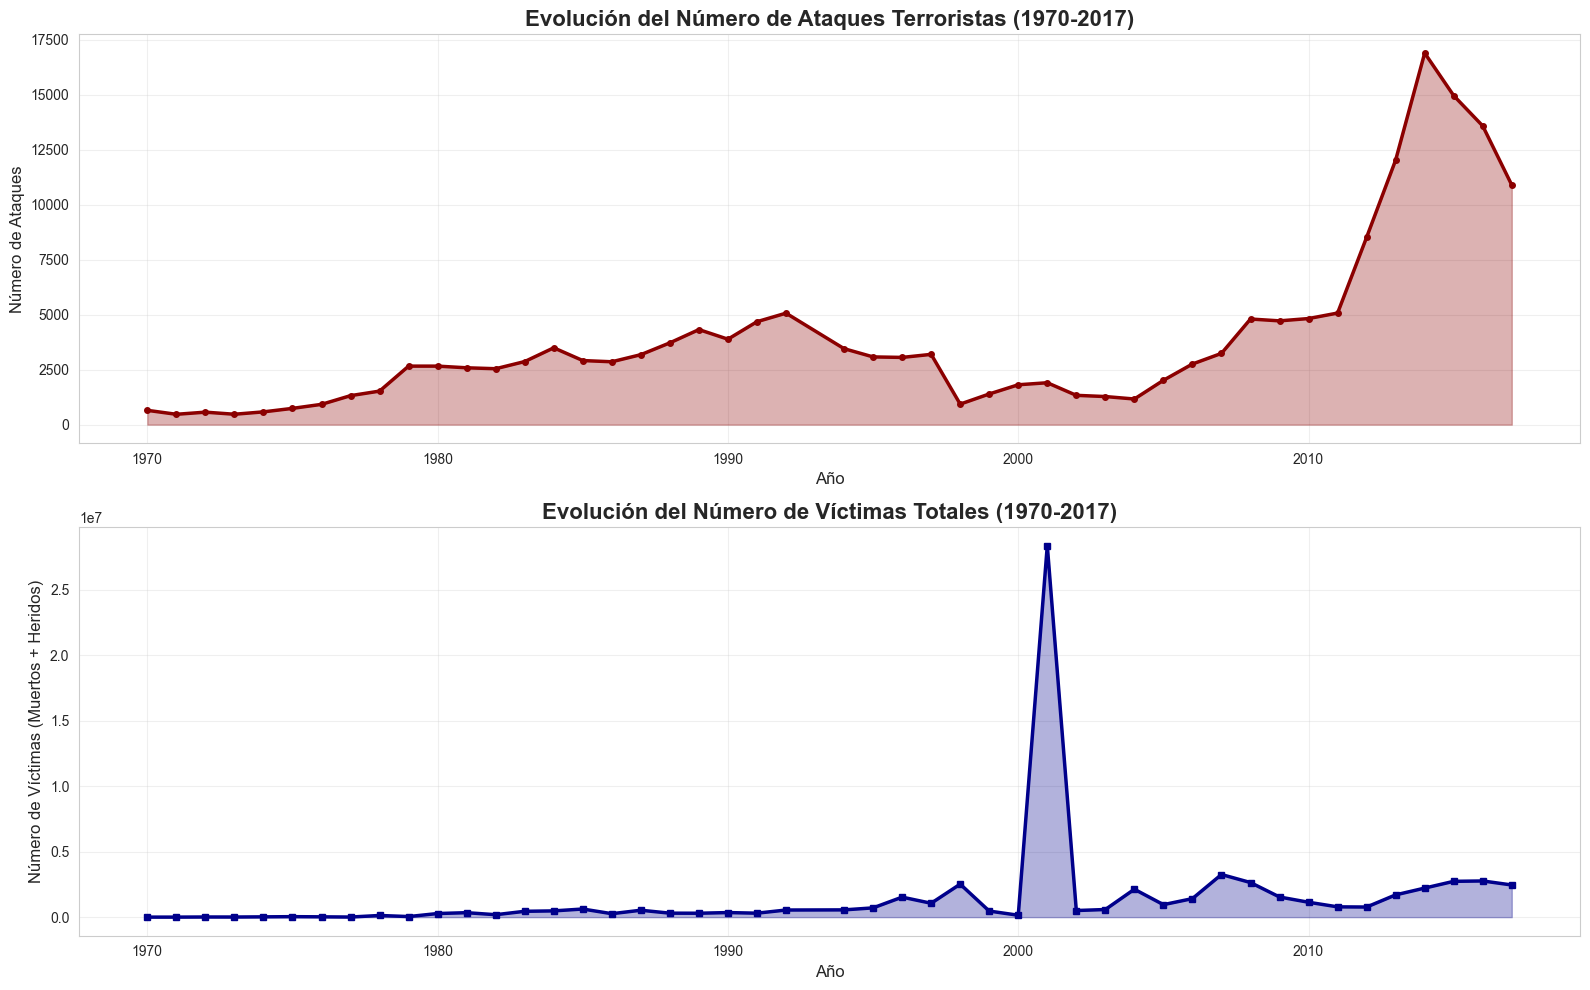

✓ Visualización 1 guardada: viz_1_evolucion_temporal.png


In [56]:
# Convertir a Pandas para visualización
ataques_año_pd = ataques_por_año.to_pandas()

# Crear gráfico de línea
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10))

# Número de ataques
ax1.plot(ataques_año_pd.index, ataques_año_pd['num_ataques'], 
         linewidth=2.5, color='darkred', marker='o', markersize=4)
ax1.fill_between(ataques_año_pd.index, ataques_año_pd['num_ataques'], 
                  alpha=0.3, color='darkred')
ax1.set_title('Evolución del Número de Ataques Terroristas (1970-2017)', 
              fontsize=16, fontweight='bold')
ax1.set_xlabel('Año', fontsize=12)
ax1.set_ylabel('Número de Ataques', fontsize=12)
ax1.grid(True, alpha=0.3)

# Víctimas totales
ax2.plot(ataques_año_pd.index, ataques_año_pd['total_victimas'], 
         linewidth=2.5, color='darkblue', marker='s', markersize=4)
ax2.fill_between(ataques_año_pd.index, ataques_año_pd['total_victimas'], 
                  alpha=0.3, color='darkblue')
ax2.set_title('Evolución del Número de Víctimas Totales (1970-2017)', 
              fontsize=16, fontweight='bold')
ax2.set_xlabel('Año', fontsize=12)
ax2.set_ylabel('Número de Víctimas (Muertos + Heridos)', fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('viz_1_evolucion_temporal.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 1 guardada: viz_1_evolucion_temporal.png")

### Visualización 2: Top 15 Países con Más Ataques

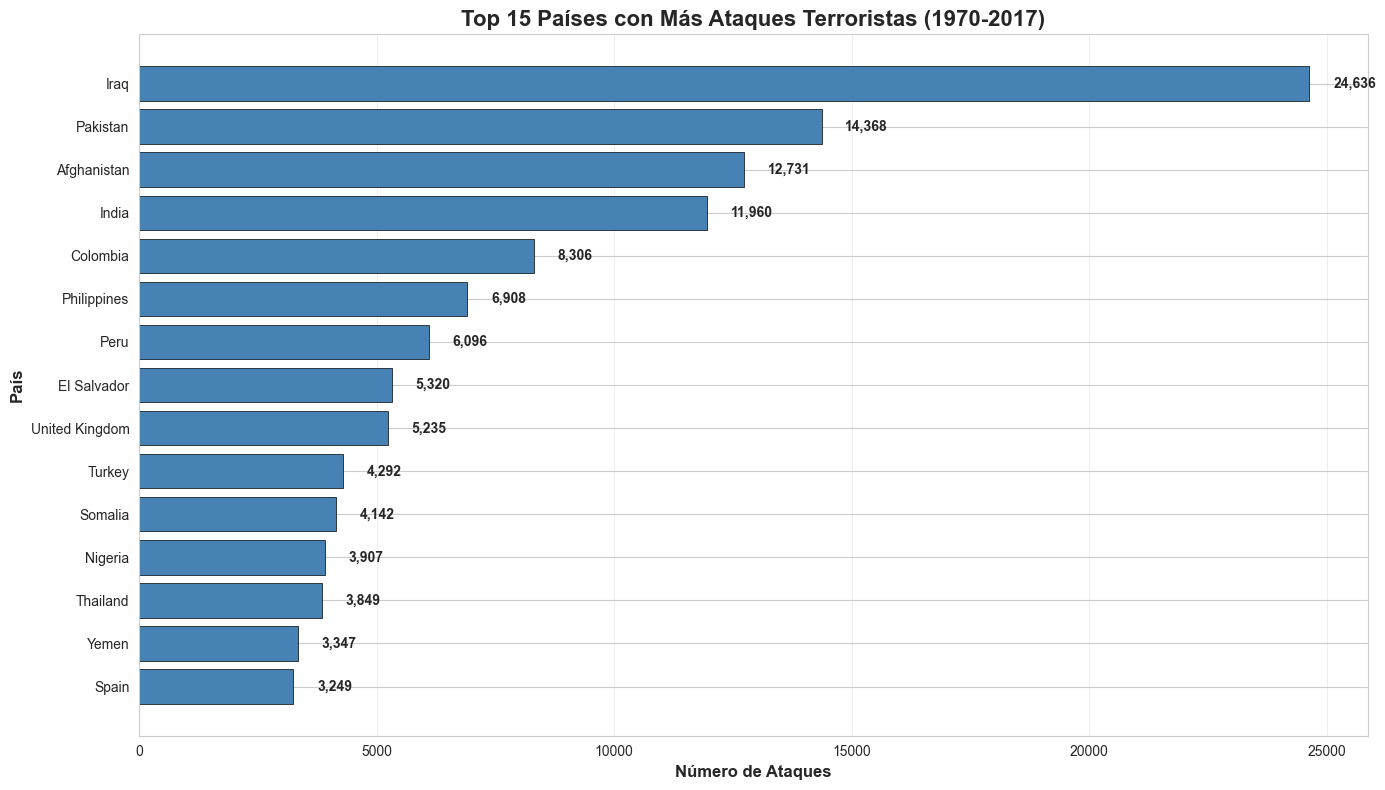

✓ Visualización 2 guardada: viz_2_top_paises.png


In [57]:
# Top 15 países - convertir de PySpark.Pandas a Pandas
top_paises = ataques_por_pais.head(15).to_pandas()

plt.figure(figsize=(14, 8))
bars = plt.barh(top_paises.index, top_paises['num_ataques'], 
                color='steelblue', edgecolor='black', linewidth=0.5)

# Agregar valores en las barras
for i, (idx, value) in enumerate(zip(top_paises.index, top_paises['num_ataques'])):
    plt.text(value + 500, i, f'{value:,.0f}', 
             va='center', fontsize=10, fontweight='bold')

plt.xlabel('Número de Ataques', fontsize=12, fontweight='bold')
plt.ylabel('País', fontsize=12, fontweight='bold')
plt.title('Top 15 Países con Más Ataques Terroristas (1970-2017)', 
          fontsize=16, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_2_top_paises.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 2 guardada: viz_2_top_paises.png")

### Visualización 3: Distribución de Tipos de Ataque

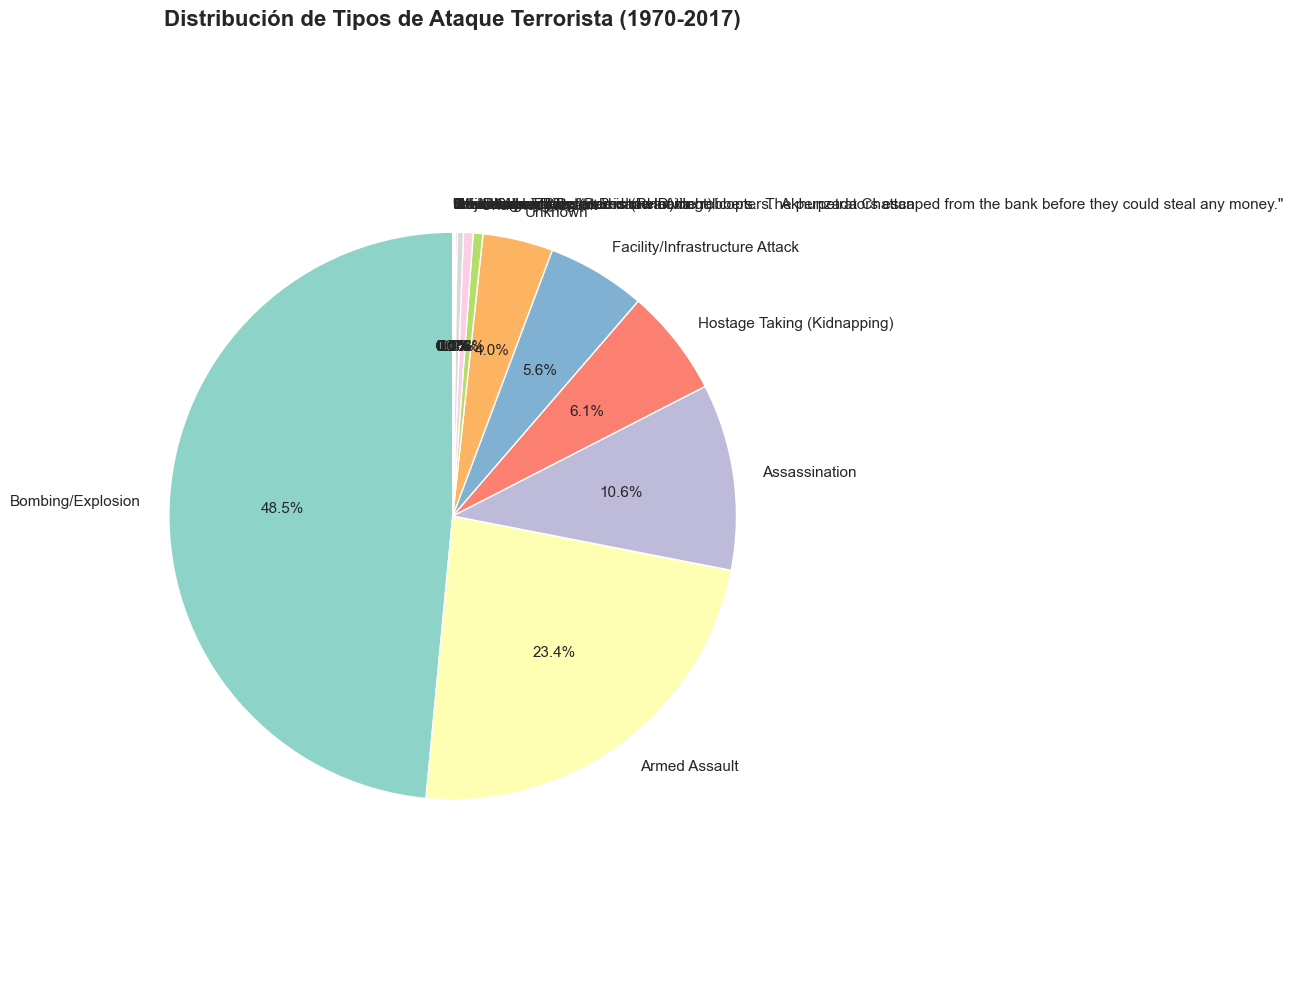

✓ Visualización 3 guardada: viz_3_tipos_ataque.png


In [58]:
# Tipos de ataque - convertir a Pandas
tipos_ataque_pd = tipos_ataque.to_pandas()

# Crear pie chart
plt.figure(figsize=(12, 10))
colors = sns.color_palette('Set3', len(tipos_ataque_pd))

plt.pie(tipos_ataque_pd['num_ataques'], 
        labels=tipos_ataque_pd.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors,
        textprops={'fontsize': 11})

plt.title('Distribución de Tipos de Ataque Terrorista (1970-2017)', 
          fontsize=16, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.savefig('viz_3_tipos_ataque.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 3 guardada: viz_3_tipos_ataque.png")

### Visualización 4: Ataques por Región

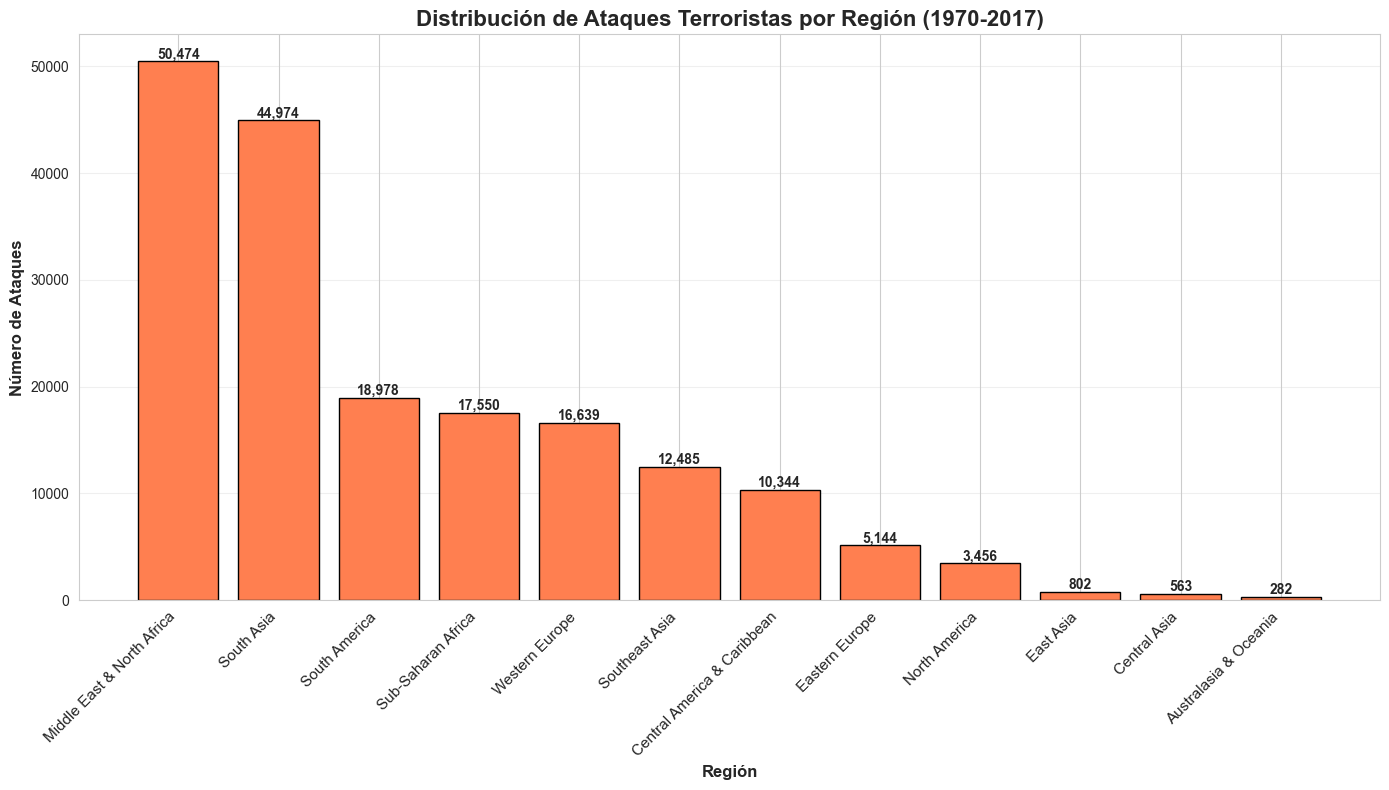

✓ Visualización 4 guardada: viz_4_ataques_region.png


In [59]:
# Ataques por región - convertir a Pandas
regiones_pd = ataques_por_region.to_pandas()

plt.figure(figsize=(14, 8))
bars = plt.bar(range(len(regiones_pd)), regiones_pd['num_ataques'], 
               color='coral', edgecolor='black', linewidth=1)

plt.xticks(range(len(regiones_pd)), regiones_pd.index, 
           rotation=45, ha='right', fontsize=11)
plt.xlabel('Región', fontsize=12, fontweight='bold')
plt.ylabel('Número de Ataques', fontsize=12, fontweight='bold')
plt.title('Distribución de Ataques Terroristas por Región (1970-2017)', 
          fontsize=16, fontweight='bold')

# Agregar valores en las barras
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_4_ataques_region.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 4 guardada: viz_4_ataques_region.png")

### Visualización 5: Top 15 Grupos Terroristas

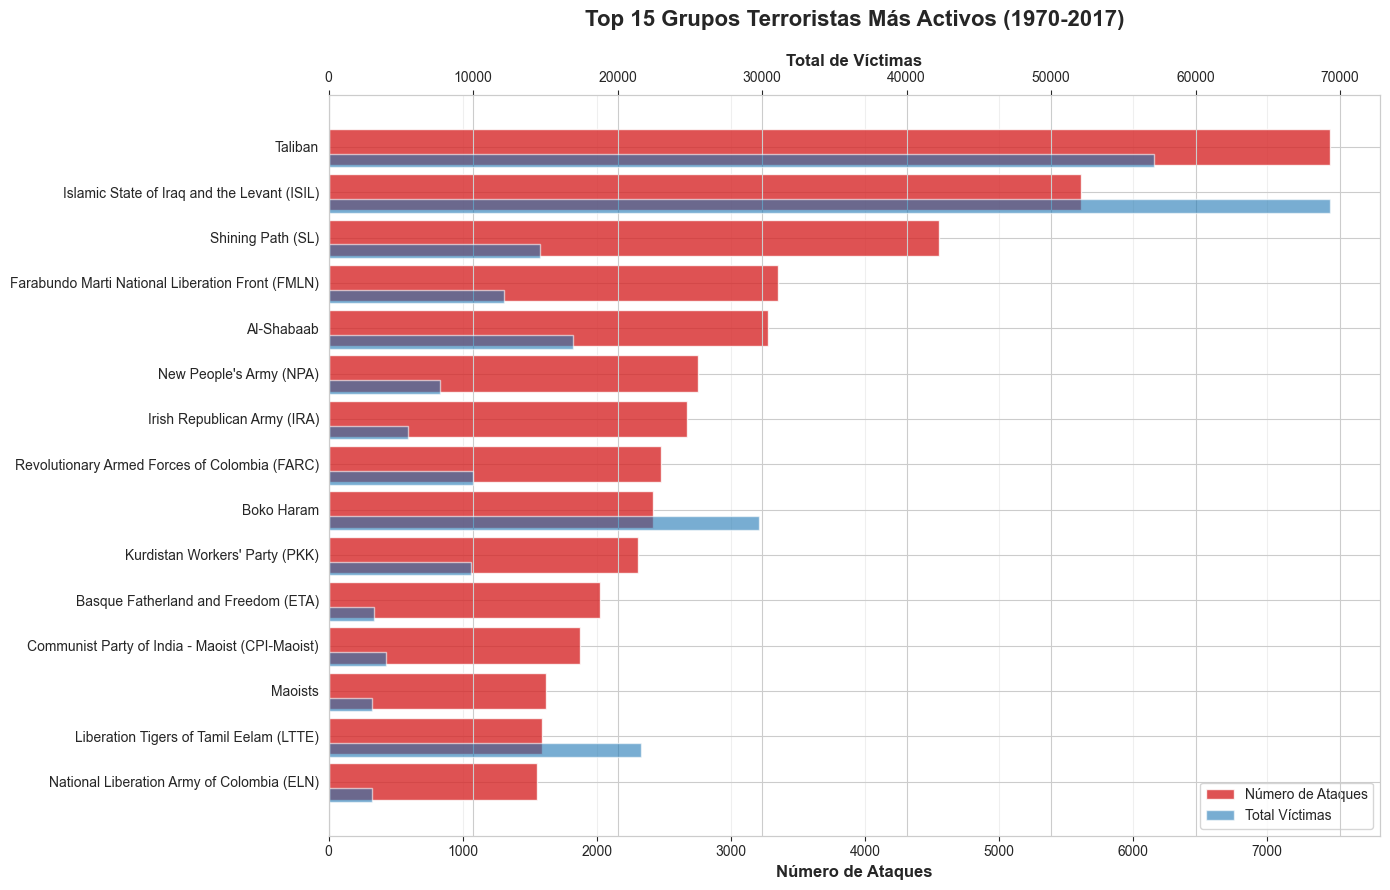

✓ Visualización 5 guardada: viz_5_top_grupos.png


In [60]:
# Top 15 grupos terroristas - convertir a Pandas
top_grupos = grupos_terroristas.head(15).to_pandas()

fig, ax = plt.subplots(figsize=(14, 9))

# Crear barras horizontales con doble información
y_pos = range(len(top_grupos))
bars1 = ax.barh(y_pos, top_grupos['num_ataques'], 
                color='#d62728', alpha=0.8, label='Número de Ataques')

# Eje secundario para víctimas
ax2 = ax.twiny()
bars2 = ax2.barh([y + 0.3 for y in y_pos], top_grupos['total_victimas'], 
                  height=0.3, color='#1f77b4', alpha=0.6, label='Total Víctimas')

ax.set_yticks(y_pos)
ax.set_yticklabels(top_grupos.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel('Número de Ataques', fontsize=12, fontweight='bold')
ax2.set_xlabel('Total de Víctimas', fontsize=12, fontweight='bold')
ax.set_title('Top 15 Grupos Terroristas Más Activos (1970-2017)', 
             fontsize=16, fontweight='bold', pad=20)

# Leyenda combinada
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax.legend(handles1 + handles2, labels1 + labels2, loc='lower right', fontsize=10)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_5_top_grupos.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 5 guardada: viz_5_top_grupos.png")

### Visualización 6: Heatmap de Ataques por Década y Región

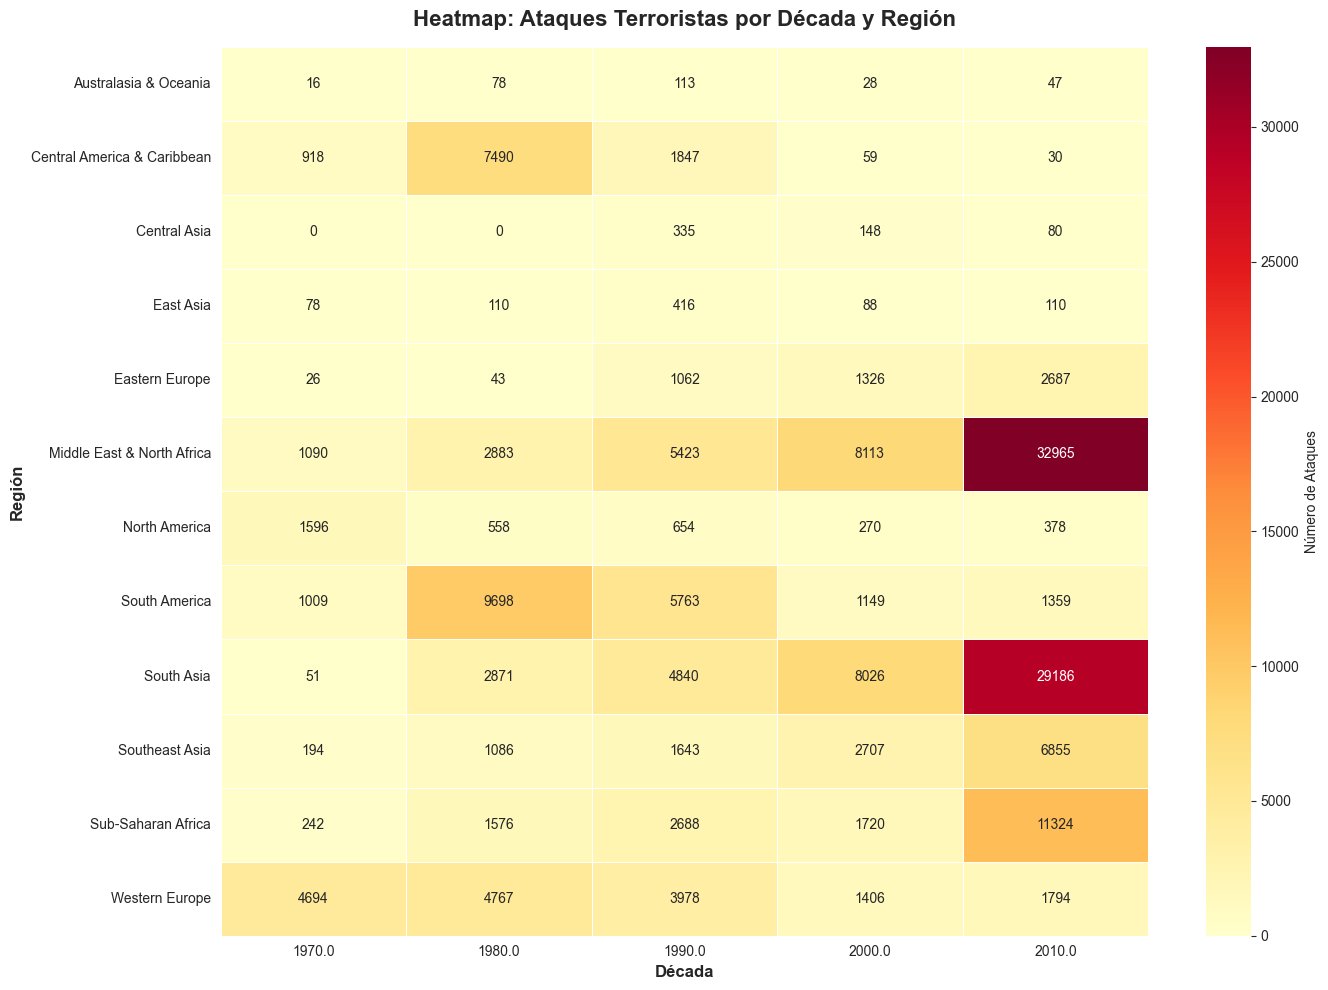

✓ Visualización 6 guardada: viz_6_heatmap_decada_region.png


In [61]:
# Crear columna de década usando PySpark.Pandas
df_clean['decada'] = (df_clean['iyear'] // 10) * 10

# Ataques por década y región usando groupby de PySpark.Pandas
heatmap_data = df_clean.groupby(['decada', 'region_txt']).size().to_frame('count')
heatmap_data = heatmap_data.reset_index()

# Convertir a Pandas para pivotar
heatmap_pd = heatmap_data.to_pandas()
heatmap_pivot = heatmap_pd.pivot(index='region_txt', 
                                  columns='decada', 
                                  values='count').fillna(0)

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_pivot, annot=True, fmt='.0f', cmap='YlOrRd', 
            linewidths=0.5, cbar_kws={'label': 'Número de Ataques'})
plt.title('Heatmap: Ataques Terroristas por Década y Región', 
          fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Década', fontsize=12, fontweight='bold')
plt.ylabel('Región', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('viz_6_heatmap_decada_region.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 6 guardada: viz_6_heatmap_decada_region.png")

### Visualización 7: Tipos de Armas Más Letales

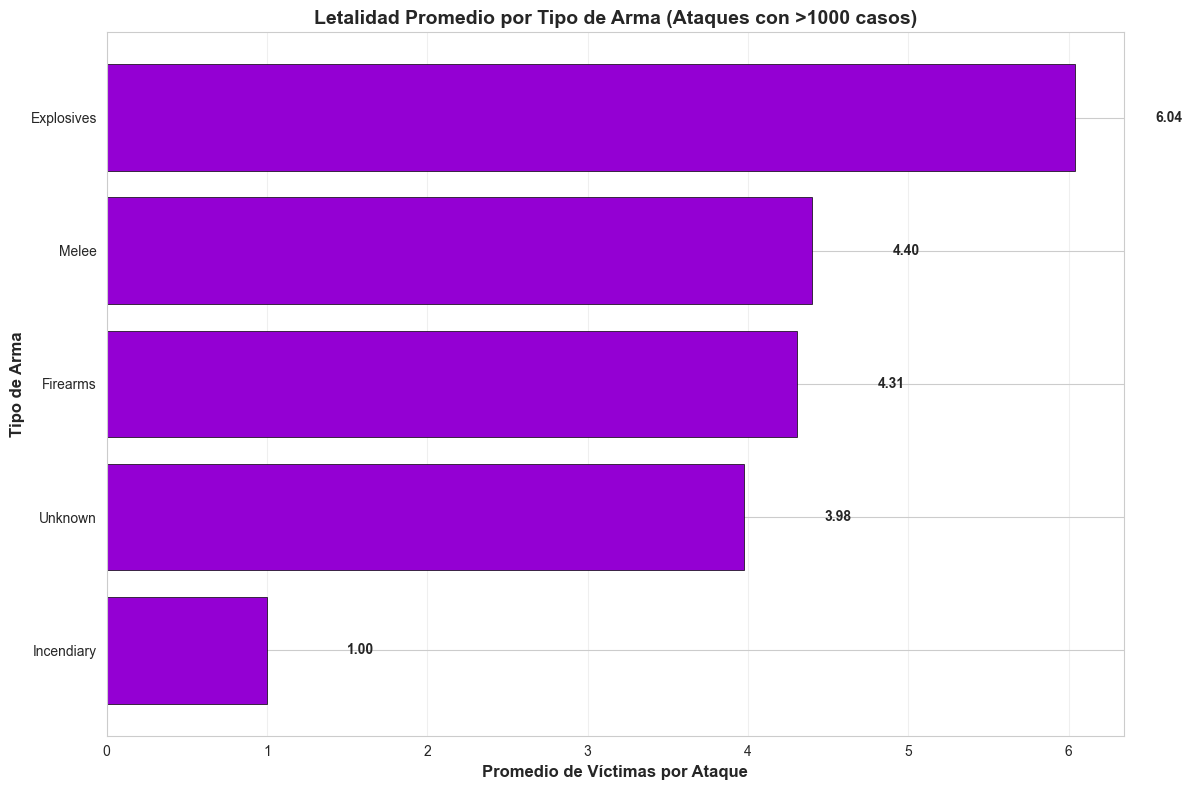

✓ Visualización 7 guardada: viz_7_armas_letales.png


In [62]:
# Armas más letales (promedio de víctimas)
# Filtrar armas con más de 1000 ataques
armas_letales = tipos_armas[tipos_armas['num_ataques'] > 1000].to_pandas()
armas_letales = armas_letales.sort_values('victimas_promedio', ascending=True)

plt.figure(figsize=(12, 8))
bars = plt.barh(armas_letales.index, 
                armas_letales['victimas_promedio'],
                color='darkviolet', edgecolor='black', linewidth=0.5)

plt.xlabel('Promedio de Víctimas por Ataque', fontsize=12, fontweight='bold')
plt.ylabel('Tipo de Arma', fontsize=12, fontweight='bold')
plt.title('Letalidad Promedio por Tipo de Arma (Ataques con >1000 casos)', 
          fontsize=14, fontweight='bold')

# Agregar valores
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
             f'{width:.2f}',
             ha='left', va='center', fontsize=10, fontweight='bold')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('viz_7_armas_letales.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 7 guardada: viz_7_armas_letales.png")

## 7. Operaciones Avanzadas con PySpark.Pandas

In [63]:
# Usar operaciones de ventana (rolling) con PySpark.Pandas
print("Calculando media móvil de ataques (ventana de 3 años):")

# Media móvil usando rolling de PySpark.Pandas
ataques_año_rolling = ataques_por_año.copy()
ataques_año_rolling['media_movil_3años'] = ataques_año_rolling['num_ataques'].rolling(window=3).mean()

print("\nPrimeras 10 filas con media móvil:")
ataques_año_rolling.head(10)

Calculando media móvil de ataques (ventana de 3 años):

Primeras 10 filas con media móvil:


,num_ataques,total_muertos,total_heridos,total_victimas,media_movil_3años
iyear,,,,,
1970.0,651,174.0,212.0,2402.0,NaN
1976.0,923,674.0,756.0,23786.0,748.000000
1978.0,1526,1458.0,1601.0,127691.0,1256.000000
1979.0,2662,2099.0,2506.0,43836.0,1835.666667
1981.0,2586,4851.0,3337.0,340927.0,2636.666667
1982.0,2544,5136.0,3342.0,185832.0,2597.333333
1984.0,3495,10449.0,5291.0,477611.0,2969.666667
1990.0,3887,7148.0,6125.0,348955.0,3977.333333
1996.0,3058,6966.0,10812.0,1528105.0,3198.333333


In [66]:
# Usar operaciones condicionales en lugar de apply (más eficiente en PySpark.Pandas)
print("Categorizando nivel de peligrosidad por número de víctimas:")

# Crear categorías usando condiciones vectorizadas
import numpy as np

df_clean['nivel_peligrosidad'] = 'Sin víctimas'  # Valor por defecto

# Aplicar condiciones en orden
df_clean.loc[df_clean['total_casualties'] >= 50, 'nivel_peligrosidad'] = 'Muy Alto'
df_clean.loc[(df_clean['total_casualties'] >= 20) & (df_clean['total_casualties'] < 50), 'nivel_peligrosidad'] = 'Alto'
df_clean.loc[(df_clean['total_casualties'] >= 5) & (df_clean['total_casualties'] < 20), 'nivel_peligrosidad'] = 'Medio'
df_clean.loc[(df_clean['total_casualties'] > 0) & (df_clean['total_casualties'] < 5), 'nivel_peligrosidad'] = 'Bajo'

print("✓ Categorización completada\n")

# Contar por categoría y convertir a pandas para mostrar
print("Distribución de nivel de peligrosidad:")
conteo = df_clean['nivel_peligrosidad'].value_counts().to_pandas()
print(conteo)

Categorizando nivel de peligrosidad por número de víctimas:
✓ Categorización completada

Distribución de nivel de peligrosidad:
Sin víctimas    74215
Bajo            66903
Medio           30984
Alto             6903
Muy Alto         2686
Name: nivel_peligrosidad, dtype: int64


## 8. Exportar Resultados

In [68]:
# Exportar resultados desde PySpark.Pandas a CSV
print("Exportando resultados...\n")

# Convertir a Pandas y guardar
ataques_por_año.to_pandas().to_csv('resultado_ataques_por_año.csv', encoding='utf-8-sig')
print("✓ Guardado: resultado_ataques_por_año.csv")

ataques_por_pais.head(50).to_pandas().to_csv('resultado_top_50_paises.csv', encoding='utf-8-sig')
print("✓ Guardado: resultado_top_50_paises.csv")

grupos_terroristas.head(50).to_pandas().to_csv('resultado_top_50_grupos.csv', encoding='utf-8-sig')
print("✓ Guardado: resultado_top_50_grupos.csv")

ataques_por_region.to_pandas().to_csv('resultado_ataques_por_region.csv', encoding='utf-8-sig')
print("✓ Guardado: resultado_ataques_por_region.csv")

Exportando resultados...

✓ Guardado: resultado_ataques_por_año.csv
✓ Guardado: resultado_top_50_paises.csv
✓ Guardado: resultado_top_50_grupos.csv
✓ Guardado: resultado_ataques_por_region.csv


## 9. Conclusiones y Hallazgos Principales

### Hallazgos Principales del Análisis GTD con PySpark.Pandas:

**1. Evolución Temporal:**
- Se observa un incremento dramático del terrorismo después del año 2000
- Los años con mayor actividad terrorista se concentran en la década de 2010
- Existe una brecha de datos en 1993

**2. Distribución Geográfica:**
- Medio Oriente y el Sur de Asia son las regiones más afectadas
- Iraq, Afganistán, Pakistán e India lideran en número de ataques
- América Latina muestra una disminución significativa comparada con los años 70-80

**3. Tipos de Ataque:**
- Los bombardeos y atentados explosivos son el tipo más común
- Los ataques armados son el segundo tipo más frecuente
- Los ataques suicidas, aunque menos frecuentes, son significativamente más letales

**4. Grupos Terroristas:**
- Grupos como Taliban, ISIS, y Boko Haram han sido extremadamente activos
- Muchos ataques permanecen sin atribución a grupos específicos
- La actividad de grupos varía significativamente por región y periodo

**5. Ventajas de usar PySpark.Pandas (Koalas):**
- Sintaxis familiar de pandas para operaciones distribuidas
- Escalabilidad automática para grandes volúmenes de datos
- Conversión fácil entre PySpark.Pandas y Pandas cuando es necesario
- Operaciones como groupby, rolling, apply funcionan de manera distribuida

### Implicaciones:

1. **Para Políticas Públicas:**
   - Necesidad de estrategias regionales diferenciadas
   - Importancia de la cooperación internacional
   - Enfoque en protección de civiles

2. **Para Investigación:**
   - Patrones geográficos y temporales claros para análisis predictivo
   - Oportunidades para estudios de efectividad de contramedidas
   - Necesidad de entender factores socioeconómicos subyacentes

3. **Uso de PySpark.Pandas:**
   - Ideal para datasets grandes que no caben en memoria
   - Permite análisis exploratorio rápido con sintaxis familiar
   - Facilita la transición de prototipos pandas a producción Spark

## 10. Resumen Final

In [65]:
# Generar resumen ejecutivo
print("="*70)
print("RESUMEN EJECUTIVO: ANÁLISIS GTD CON PYSPARK.PANDAS")
print("="*70)

# Estadísticas generales usando PySpark.Pandas
total_ataques = len(df_clean)
total_muertos = df_clean['nkill'].sum()
total_heridos = df_clean['nwound'].sum()

print(f"\n📊 DATOS PROCESADOS CON PYSPARK.PANDAS:")
print(f"  • Total de ataques analizados: {total_ataques:,}")
print(f"  • Periodo de análisis: {df_clean['iyear'].min()}-{df_clean['iyear'].max()}")
print(f"  • Columnas utilizadas: {len(df_clean.columns)}")
print(f"  • Framework: PySpark.Pandas (Koalas API)")

print(f"\n💀 IMPACTO HUMANO:")
print(f"  • Total de muertos: {total_muertos:,.0f}")
print(f"  • Total de heridos: {total_heridos:,.0f}")
print(f"  • Total de víctimas: {(total_muertos + total_heridos):,.0f}")

# Regiones más afectadas
print(f"\n🌍 DISTRIBUCIÓN GEOGRÁFICA:")
top_3_regiones = ataques_por_region.head(3).to_pandas()
for i, (region, row) in enumerate(top_3_regiones.iterrows(), 1):
    print(f"  {i}. {region}: {row['num_ataques']:,.0f} ataques")

# Tipos de ataque más comunes
print(f"\n💣 TIPOS DE ATAQUE MÁS COMUNES:")
top_3_tipos = tipos_ataque.head(3).to_pandas()
for i, (tipo, row) in enumerate(top_3_tipos.iterrows(), 1):
    print(f"  {i}. {tipo}: {row['num_ataques']:,.0f} casos")

# Archivos generados
print(f"\n📁 RESULTADOS GENERADOS:")
print(f"  • Visualizaciones: 7 gráficas guardadas")
print(f"  • Archivos CSV: 4 datasets de resultados")
print(f"  • Análisis: Operaciones distribuidas con PySpark.Pandas")

print(f"\n✨ VENTAJAS DE PYSPARK.PANDAS:")
print(f"  • Sintaxis familiar de pandas")
print(f"  • Procesamiento distribuido automático")
print(f"  • Escalabilidad para grandes datasets")
print(f"  • Conversión fácil a/desde pandas")

print("\n" + "="*70)
print("ANÁLISIS COMPLETADO EXITOSAMENTE CON PYSPARK.PANDAS")
print("="*70)

RESUMEN EJECUTIVO: ANÁLISIS GTD CON PYSPARK.PANDAS

📊 DATOS PROCESADOS CON PYSPARK.PANDAS:
  • Total de ataques analizados: 181,691
  • Periodo de análisis: 1970-2017
  • Columnas utilizadas: 36
  • Framework: PySpark.Pandas (Koalas API)

💀 IMPACTO HUMANO:
  • Total de muertos: 410,133
  • Total de heridos: 520,977
  • Total de víctimas: 931,110

🌍 DISTRIBUCIÓN GEOGRÁFICA:
  1. Middle East & North Africa: 50,474 ataques
  2. South Asia: 44,974 ataques
  3. South America: 18,978 ataques

💣 TIPOS DE ATAQUE MÁS COMUNES:
  1. Bombing/Explosion: 88,101 casos
  2. Armed Assault: 42,566 casos
  3. Assassination: 19,285 casos

📁 RESULTADOS GENERADOS:
  • Visualizaciones: 7 gráficas guardadas
  • Archivos CSV: 4 datasets de resultados
  • Análisis: Operaciones distribuidas con PySpark.Pandas

✨ VENTAJAS DE PYSPARK.PANDAS:
  • Sintaxis familiar de pandas
  • Procesamiento distribuido automático
  • Escalabilidad para grandes datasets
  • Conversión fácil a/desde pandas

ANÁLISIS COMPLETADO EXITO